# 00 · Overview

This repository contains a sample of patent publications (2021–2026) selected across
**32 technology fields**, and a set of notebooks to explore it.

**How to use the notebooks**
- Run them in order, from the `notebooks/` folder. Each notebook starts by saying what it needs and what it produces.
- Run a cell with `Shift + Enter`. Read the text before the code: it says what to look at.
- Nothing here is hard to break. If something goes wrong, restart the kernel and run all cells again.

**This notebook**: explains the main concepts, checks that your setup works, and shows what one patent looks like.

## 1. Main concepts

**Patent publication.** A document published by a patent office. The same invention can be published several times
(application, granted patent, copies in other countries). In this repository one row is one *publication*.

**Publication number**, for example `US-2022000739-A1`: office (`US`) – number – kind code (`A1`).
The kind code tells the type of document (application, granted patent, utility model...), but its meaning depends on the office.

**IPC (International Patent Classification).** A hierarchy of codes that describes the technology of a patent.
A patent usually has several codes. Example: `G06N3/08`

| Part | Code | Level |
|---|---|---|
| G | `G` | section (Physics) |
| 06 | `G06` | class |
| N | `G06N` | subclass |
| 3/00 | `G06N3/00` | main group |
| 3/08 | `G06N3/08` | subgroup |

**WIPO technology field.** WIPO groups IPC codes into 35 *technology fields*, and fields into 5 *sectors*.
The mapping is a list of rules, published by WIPO as an Excel file.
We selected 2,000 publications for each of the fields 1–32. Fields 33–35 ("Other fields") are **not** in the data.

## 2. Check the setup

In [1]:
from pathlib import Path
import textwrap
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_colwidth", 80)
sns.set_theme(style="whitegrid")

RAW = Path("../data/raw")
IPC = Path("../ipc")

# list the files we expect to find, with their size in MB
expected = sorted(RAW.glob("*.csv")) + [IPC / "ipc_technology.xlsx", IPC / "ipc_titles.csv"]
for f in expected:
    print(f"{f.stat().st_size / 1e6:7.1f} MB   {f}")

   23.9 MB   ../data/raw/patents_chemistry_2021-2026_n2000.csv
   18.6 MB   ../data/raw/patents_electrical_engineering_2021-2026_n2000.csv
   11.6 MB   ../data/raw/patents_instruments_2021-2026_n2000.csv
   20.0 MB   ../data/raw/patents_mechanical_engineering_2021-2026_n2000.csv
    0.0 MB   ../ipc/ipc_technology.xlsx
   27.0 MB   ../ipc/ipc_titles.csv


If a file is missing, check that you started Jupyter from the right folder (the notebook must be in `notebooks/`).

## 3. One patent

We read one raw file and print a random publication.

In [2]:
inst = pd.read_csv(RAW / "patents_instruments_2021-2026_n2000.csv", dtype=str)
row = inst.sample(1, random_state=7).iloc[0]

for col in ["wipo_sector", "wipo_field_number", "wipo_field_name", "publication_number", "publication_date", "title_en"]:
    print(f"{col:20s} {row[col]}")
print("\nabstract_en:")
print(textwrap.fill(row["abstract_en"], 100))
print("\nipc_codes:", row["ipc_codes"])

wipo_sector          Instruments
wipo_field_number    9
wipo_field_name      Optics
publication_number   WO-2025114755-A1
publication_date     20250605
title_en             Minimally invasive optical forward viewing probe

abstract_en:
An optical probe assembly including a lens assembly extending along a central axis for optically
coupling to an optical fiber. The lens assembly can have a forward facing exit window. The exit
window can have an exit lens with a convex exit surface. The exit lens can extend from a periphery
of the exit window and terminate partway across the exit window. The convex exit surface of the exit
lens can be tilted inwardly relative to the central axis. The exit lens can bend light received from
the optical fiber forwardly out of the exit window at an outward angle relative to the central axis.

ipc_codes: A61B5/00;G01B9/02;G01B9/02091;G02B6/26


Note that `wipo_field_*` is the field **for which the patent was selected**.
The IPC codes can point to other technologies as well. We will measure this in notebook 05.

## 4. What an IPC code means

`ipc/ipc_titles.csv` has the official English title of every IPC symbol, built from the WIPO scheme
(see `src/build_ipc_titles.py`). We use it to read the code `G06N3/08`.

In [3]:
titles = pd.read_csv(IPC / "ipc_titles.csv", dtype=str, keep_default_na=False)
print(titles.shape)
titles.head()

(80146, 8)


,symbol,level,title,short_title,full_title,depth,parent,source
0,A,section,HUMAN NECESSITIES,Human necessities,,0,,scheme_2026.01
1,A01,class,AGRICULTURE; FORESTRY; ANIMAL HUSBANDRY; HUNTING; TRAPPING; FISHING,Agriculture,,2,A,scheme_2026.01
2,A01B,subclass,"SOIL WORKING IN AGRICULTURE OR FORESTRY; PARTS, DETAILS, OR ACCESSORIES OF A...",Soil working in agriculture or forestry,,4,A01,scheme_2026.01
3,A01B1/00,main_group,Hand tools,Hand tools,Hand tools,5,A01B,scheme_2026.01
4,A01B1/02,subgroup,Spades; Shovels,Spades,Hand tools > Spades; Shovels,1,A01B1/00,scheme_2026.01


In [4]:
# follow the chain of parents, from the code up to its section
lookup = titles.set_index("symbol")
symbol = "G06N3/08"
while symbol:
    r = lookup.loc[symbol]
    print(f"{r['level']:<11} {symbol:<10} {r['short_title']}")
    symbol = r["parent"]

subgroup    G06N3/08   Learning methods
subgroup    G06N3/02   Neural networks
main_group  G06N3/00   Computing arrangements based on biological models
subclass    G06N       Computing arrangements based on specific computational models
class       G06        Computing or calculating
section     G          Physics


## 5. The 35 WIPO fields and what we have

The WIPO file lists, for each field, the IPC rules. `%` means "any ending": `G06Q%` is every code that starts with `G06Q`.

In [5]:
rules = pd.read_excel(IPC / "ipc_technology.xlsx", header=6)
rules = rules[["Field_number", "Sector_en", "Field_en", "IPC_code"]]

fields = (
    rules.groupby(["Field_number", "Sector_en", "Field_en"])
    .size()
    .rename("n_rules")
    .reset_index()
)
fields["in_corpus"] = fields["Field_number"] <= 32
fields

,Field_number,Sector_en,Field_en,n_rules,in_corpus
0,1,Electrical engineering,"Electrical machinery, apparatus, energy",30,True
1,2,Electrical engineering,Audio-visual technology,18,True
2,3,Electrical engineering,Telecommunications,10,True
3,4,Electrical engineering,Digital communication,3,True
4,5,Electrical engineering,Basic communication processes,10,True
5,6,Electrical engineering,Computer technology,17,True
6,7,Electrical engineering,IT methods for management,1,True
7,8,Electrical engineering,Semiconductors,2,True
8,9,Instruments,Optics,10,True
9,10,Instruments,Measurement,45,True


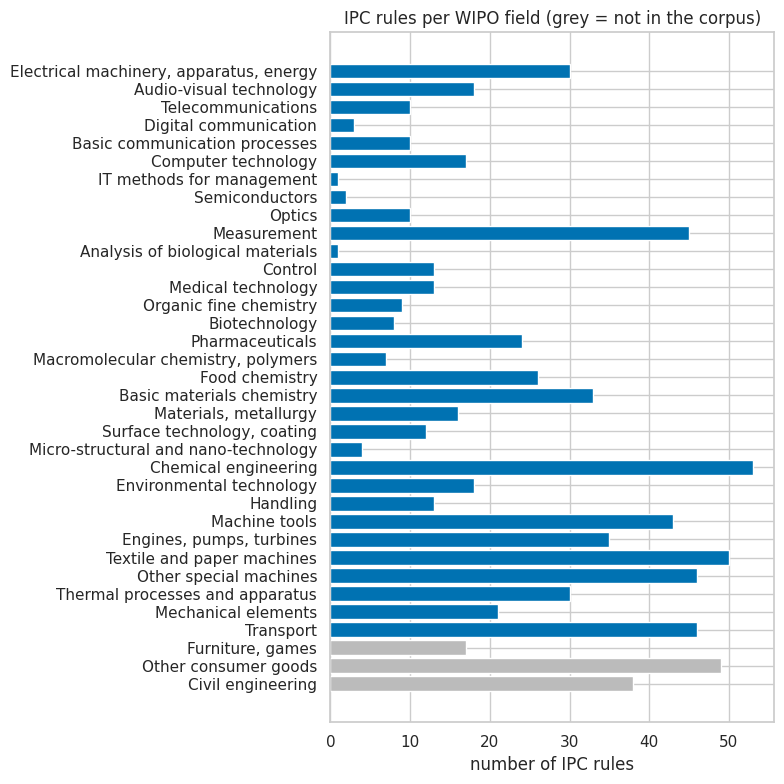

In [6]:
# number of rules per field: some fields are defined by a few rules, others by dozens
fig, ax = plt.subplots(figsize=(8, 8))
plot = fields.sort_values("Field_number", ascending=False)
colors = ["#bbbbbb" if not c else "#0072B2" for c in plot["in_corpus"]]
ax.barh(plot["Field_en"], plot["n_rules"], color=colors)
ax.set_xlabel("number of IPC rules")
ax.set_title("IPC rules per WIPO field (grey = not in the corpus)")
plt.tight_layout()
plt.show()

## Where to go next

- `01_read_raw_data`: read the four CSV files and check them.
- `02_merge_and_clean`: build one merged, cleaned file.